In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math


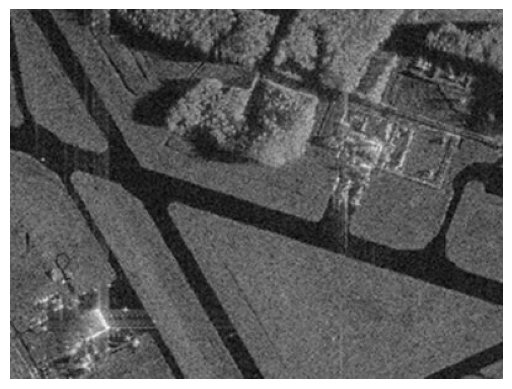

In [8]:
image = cv2.imread('/content/sar_1.jpg')

if image is None:
    raise FileNotFoundError("Изображение sar_1.jpg не найдено")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.axis('off')
plt.show()

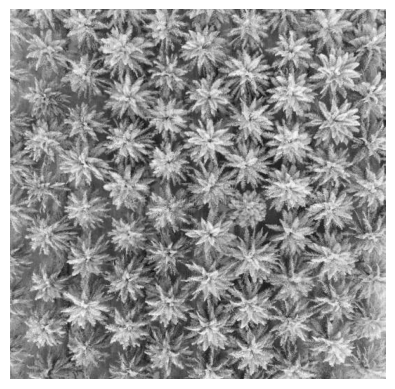

In [5]:
image = cv2.imread('/content/palm_1.JPG')

if image is None:
    raise FileNotFoundError("Изображение palm_1.JPG не найдено")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.axis('off')
plt.show()

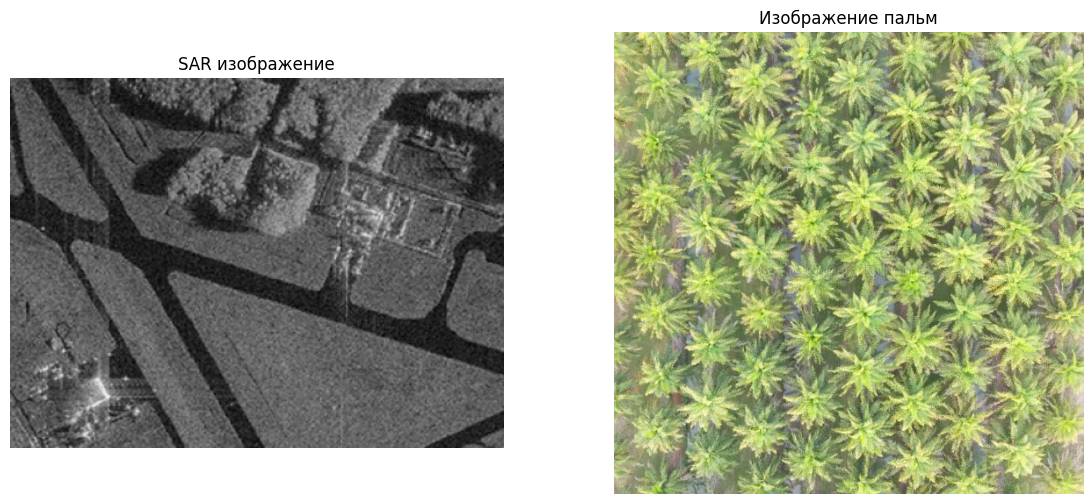

In [9]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('SAR изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(image_palm, cv2.COLOR_BGR2RGB))
plt.title('Изображение пальм')
plt.axis('off')

plt.show()

Задание 1


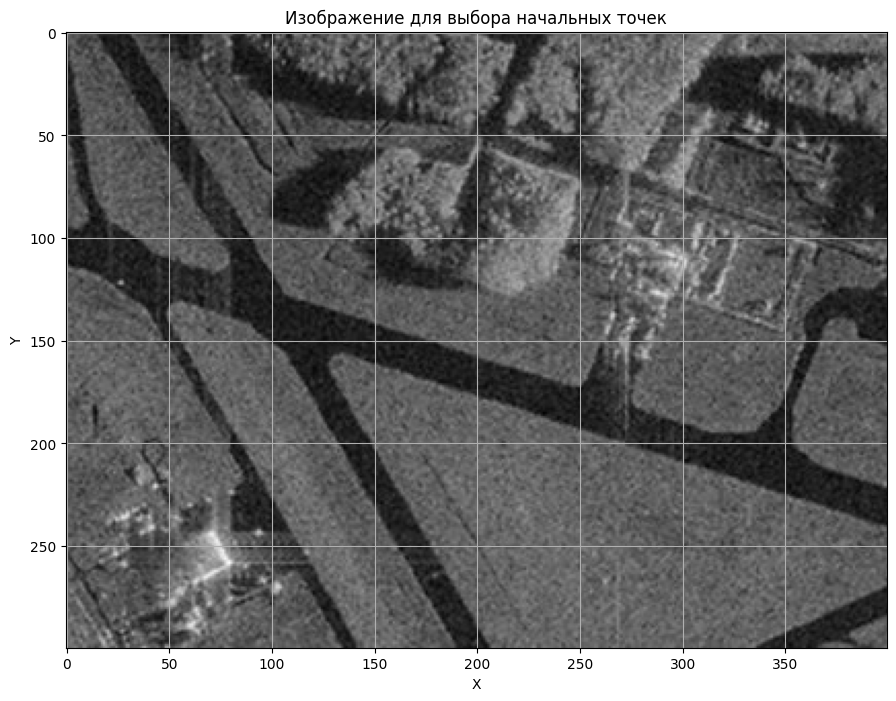

In [63]:
# Отображаем изображение с координатной сеткой
# для выбора начальных точек

plt.figure(figsize=(12, 8))
plt.imshow(image_gray, cmap='gray')

plt.title('Изображение для выбора начальных точек')
plt.xlabel('X')
plt.ylabel('Y')

plt.grid(True)
plt.show()

In [65]:
# Критерий однородности на основе среднего значения

def homo_average(img, mask, points, T):

    # Вычисляем среднюю яркость выделенной области
    av_val = img[mask > 0].mean()

    # Проверяем, насколько яркость новых пикселей
    # отличается от среднего значения
    return np.abs(
        img[points].astype(float) - av_val
    ) <= T

In [64]:
def region_growing(image, seed_point, homo_fun, r, T):

    mask = np.zeros(image.shape, dtype=np.uint8)
    mask[seed_point] = 1

    kernel = np.ones((2*r + 1, 2*r + 1), np.uint8)

    count = 1

    while count > 0:

        neighbors = cv2.dilate(mask, kernel)

        candidates = (neighbors > 0) & (mask == 0)

        points = np.where(candidates)

        if len(points[0]) == 0:
            break

        accepted = homo_fun(image, mask, points, T)

        local_mask = np.zeros(image.shape, dtype=np.uint8)

        local_mask[
            points[0][accepted],
            points[1][accepted]
        ] = 1

        count = np.count_nonzero(local_mask)

        mask += local_mask

    return mask * 255

In [101]:
# Начальные точки внутри участков газона
# Формат координат: (Y, X)

seed_points = [
    (250, 250),
    (100, 100),
    (150, 315),
    (70, 35),
    (160, 370),
    (150, 200),
    (200, 100)
]

# Проверяем, что все точки находятся внутри изображения
for y, x in seed_points:
    assert 0 <= y < image_gray.shape[0] and \
           0 <= x < image_gray.shape[1], \
           f"Точка {(y, x)} находится за пределами изображения"



print("Все начальные точки находятся внутри изображения")

Все начальные точки находятся внутри изображения


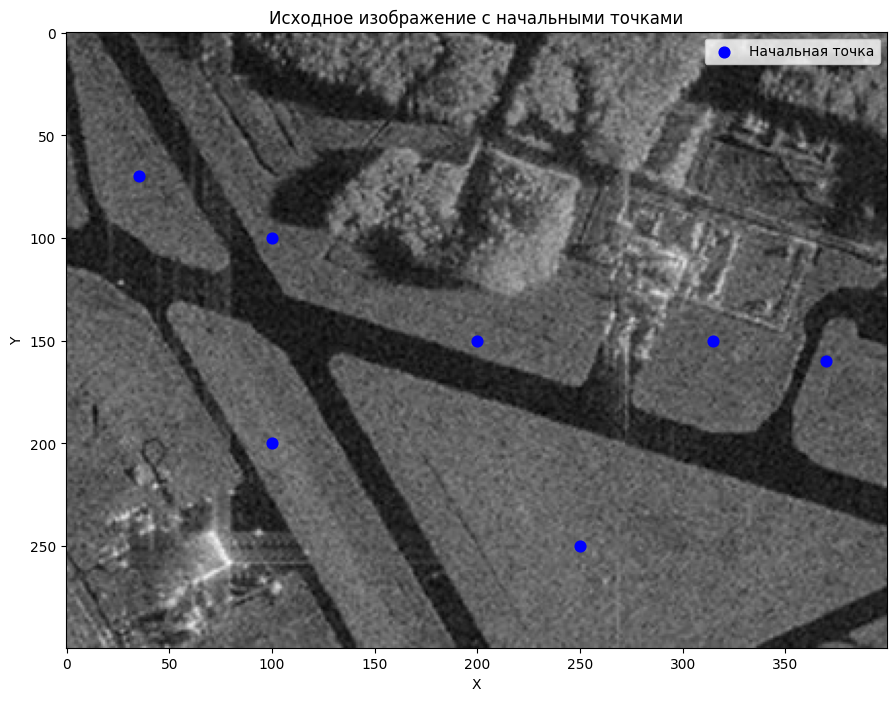

In [102]:
# Отображаем исходное изображение с начальными точками

plt.figure(figsize=(12, 8))

plt.imshow(image_gray, cmap='gray')

# Отмечаем начальные точки синим цветом
for i, (y, x) in enumerate(seed_points):
    plt.scatter(x, y, color='blue', s=60, label='Начальная точка' if i == 0 else "")

plt.title('Исходное изображение с начальными точками')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(False)
plt.show()

In [103]:
# Создаем общую маску
mask_total = np.zeros(image_gray.shape, dtype=np.uint8)

# Запускаем алгоритм для каждой начальной точки
for seed in seed_points:

    mask_part = region_growing(
        image_gray,
        seed,
        homo_average,
        r=1,
        T=8
    )

    # Объединяем выделенные области
    mask_total = np.maximum(mask_total, mask_part)

print("Количество выделенных пикселей:",
      np.count_nonzero(mask_total))

Количество выделенных пикселей: 31232


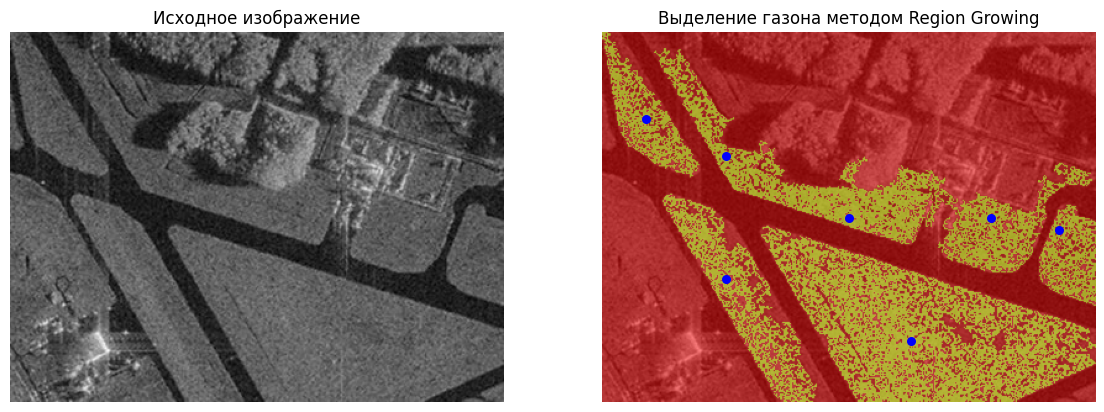

In [104]:
plt.figure(figsize=(14, 7))

# Исходное изображение
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

# Результат разрастания регионов
plt.subplot(1, 2, 2)
plt.imshow(image_gray, cmap='gray')
plt.imshow(mask_total, cmap='autumn', alpha=0.5)

for y, x in seed_points:
    plt.scatter(x, y, color='blue', s=30)

plt.title('Выделение газона методом Region Growing')
plt.axis('off')

plt.show()

Задание 2

In [105]:
# Критерий однородности на основе медианного значения

def homo_median(img, mask, points, T):

    # Вычисляем медианную яркость выделенной области
    median_val = np.median(img[mask > 0])

    # Проверяем отличие яркости новых пикселей
    # от медианного значения
    return np.abs(
        img[points].astype(float) - median_val
    ) <= T

In [106]:
# Создаем маску для критерия среднего
mask_average = np.zeros(image_gray.shape, dtype=np.uint8)

for seed in seed_points:

    part = region_growing(
        image_gray,
        seed,
        homo_average,
        r=1,
        T=8
    )

    mask_average = np.maximum(mask_average, part)

In [107]:
# Создаем маску для критерия медианы
mask_median = np.zeros(image_gray.shape, dtype=np.uint8)

for seed in seed_points:

    part = region_growing(
        image_gray,
        seed,
        homo_median,
        r=1,
        T=8
    )

    mask_median = np.maximum(mask_median, part)

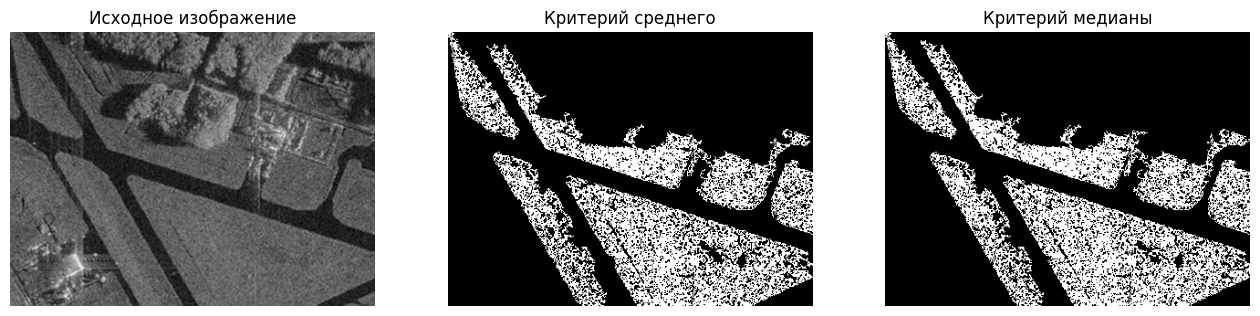

In [108]:
plt.figure(figsize=(16, 6))

# Исходное изображение
plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

# Результат с использованием среднего
plt.subplot(1, 3, 2)
plt.imshow(mask_average, cmap='gray')
plt.title('Критерий среднего')
plt.axis('off')

# Результат с использованием медианы
plt.subplot(1, 3, 3)
plt.imshow(mask_median, cmap='gray')
plt.title('Критерий медианы')
plt.axis('off')

plt.show()

In [109]:
# Подсчитываем количество выделенных пикселей
average_pixels = np.count_nonzero(mask_average)
median_pixels = np.count_nonzero(mask_median)

print("Результаты сравнения:")
print("--------------------------------")
print("Критерий среднего:", average_pixels, "пикселей")
print("Критерий медианы:", median_pixels, "пикселей")

print("--------------------------------")

if average_pixels > median_pixels:
    print("Критерий среднего выделил большую область")
elif median_pixels > average_pixels:
    print("Критерий медианы выделил большую область")
else:
    print("Оба критерия выделили одинаковое количество пикселей")

Результаты сравнения:
--------------------------------
Критерий среднего: 31232 пикселей
Критерий медианы: 32879 пикселей
--------------------------------
Критерий медианы выделил большую область


Задание 3

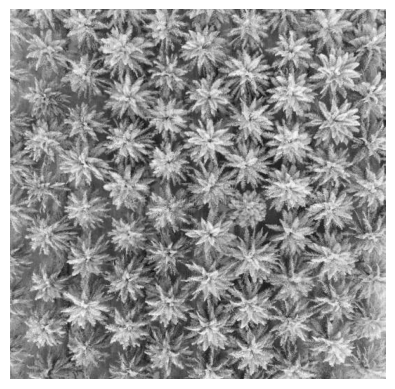

In [110]:
image = cv2.imread('/content/palm_1.JPG')

if image is None:
    raise FileNotFoundError("Изображение palm_1.JPG не найдено")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.axis('off')
plt.show()

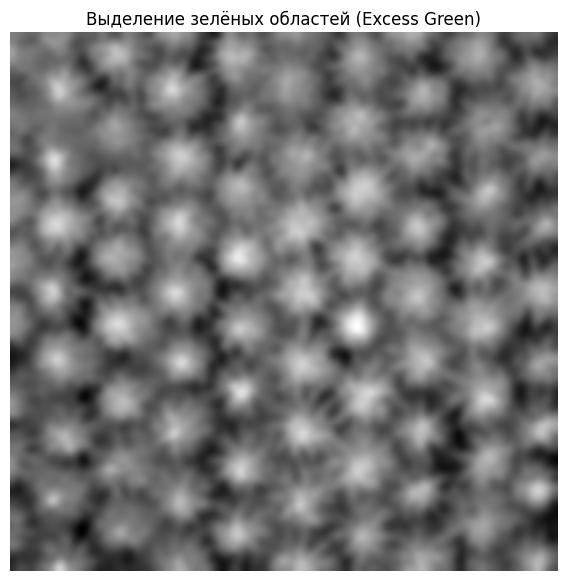

In [111]:
# Переводим изображение в RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Вычисляем показатель Excess Green
R = image_rgb[:, :, 0].astype(float)
G = image_rgb[:, :, 1].astype(float)
B = image_rgb[:, :, 2].astype(float)

exg = 2 * G - R - B

# Сглаживаем изображение
exg_smooth = cv2.GaussianBlur(
    exg.astype(np.float32),
    (0, 0),
    sigmaX=4
)

plt.figure(figsize=(9, 7))
plt.imshow(exg_smooth, cmap='gray')
plt.title('Выделение зелёных областей (Excess Green)')
plt.axis('off')
plt.show()

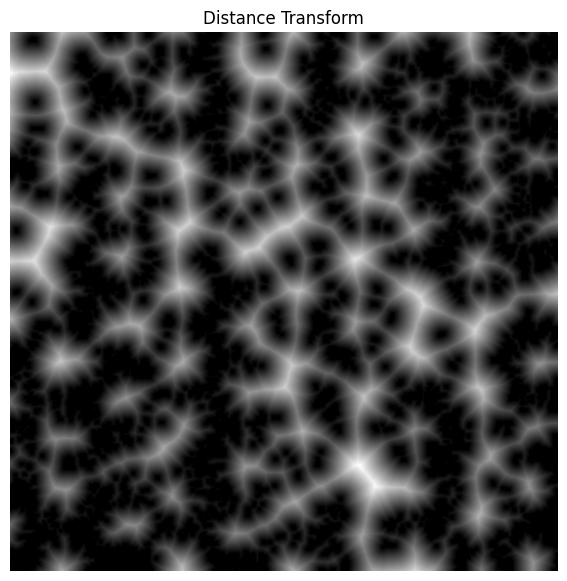

In [49]:
# Переводим изображение в HSV
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

H, S, V = cv2.split(image_hsv)

# Создаём маску растительности
thresh = (
    (H >= 20) &
    (H <= 100) &
    (S > 70) &
    (V > 50)
).astype(np.uint8)

# Убираем небольшие шумы
kernel = np.ones((3, 3), np.uint8)

thresh = cv2.morphologyEx(
    thresh,
    cv2.MORPH_CLOSE,
    kernel
)

dist = cv2.distanceTransform(
    thresh,
    cv2.DIST_L2,
    5
)

plt.figure(figsize=(9, 7))
plt.imshow(dist, cmap='gray')
plt.title('Distance Transform')
plt.axis('off')
plt.show()

Найдено центров макушек: 68


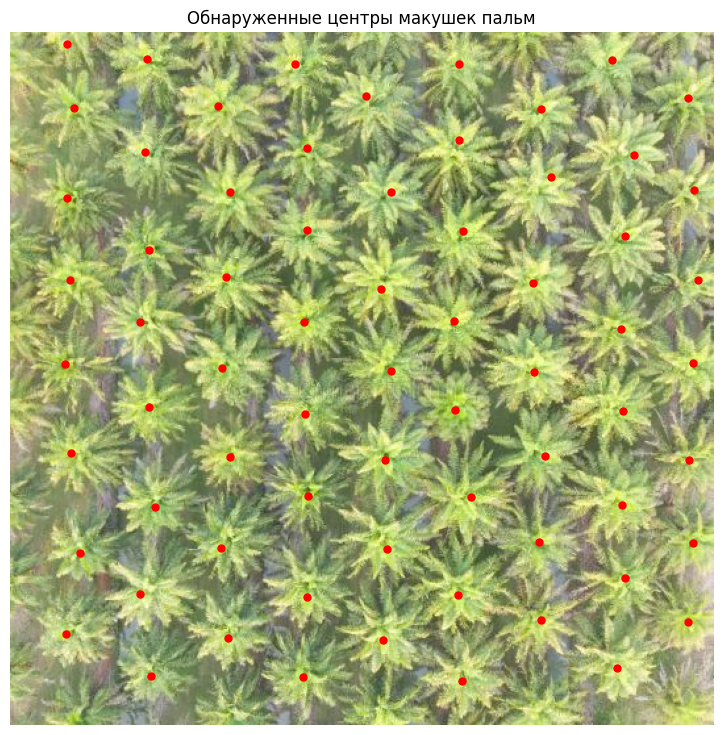

In [50]:
from skimage.feature import peak_local_max

coordinates = peak_local_max(
    exg_smooth,
    min_distance=17,
    threshold_abs=np.percentile(exg_smooth, 70),
    exclude_border=8
)

print("Найдено центров макушек:", len(coordinates))

plt.figure(figsize=(10, 9))

plt.imshow(image_rgb)

plt.scatter(
    coordinates[:, 1],
    coordinates[:, 0],
    color='red',
    s=25
)

plt.title('Обнаруженные центры макушек пальм')
plt.axis('off')
plt.show()

In [51]:
markers = np.zeros(image_gray.shape, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

print("Количество маркеров:", len(coordinates))

Количество маркеров: 68


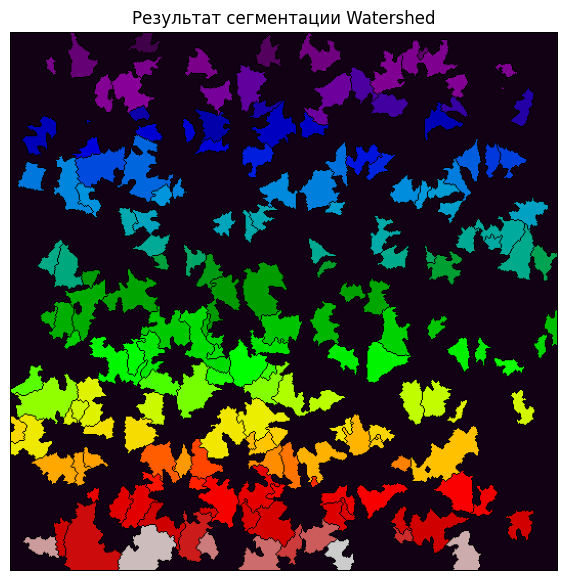

In [42]:
markers = cv2.watershed(
    image.copy(),
    markers.astype(np.int32)
)

plt.figure(figsize=(9, 7))
plt.imshow(markers, cmap='nipy_spectral')
plt.title('Результат сегментации Watershed')
plt.axis('off')
plt.show()

In [52]:
from skimage.segmentation import watershed

labels = watershed(
    -dist,
    markers,
    mask=(thresh > 0)
)

palm_count = len(np.unique(labels[labels > 0]))

print("Количество сегментированных областей:", palm_count)

Количество сегментированных областей: 68


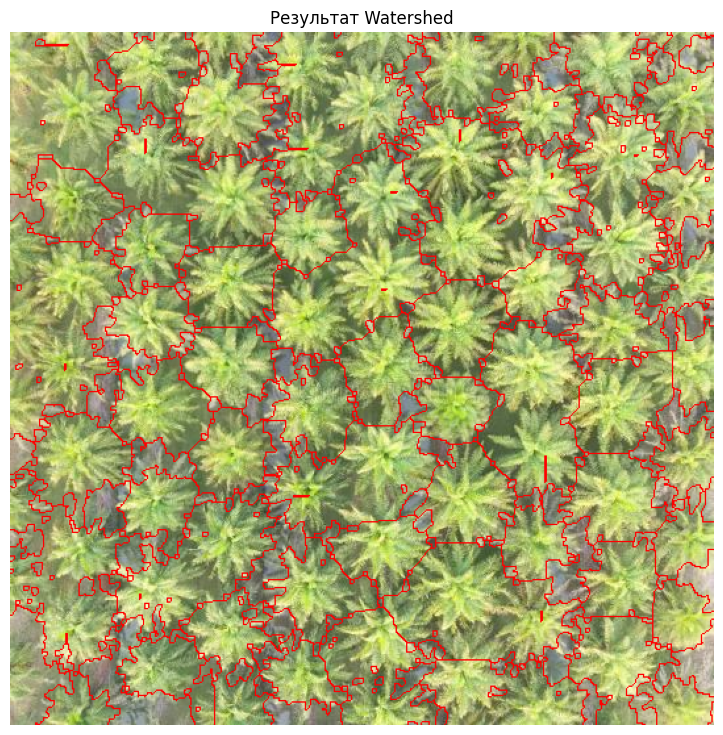

In [53]:
result = image_rgb.copy()

# Выделяем границы сегментов
boundaries = np.zeros(labels.shape, dtype=bool)

boundaries[1:, :] |= labels[1:, :] != labels[:-1, :]
boundaries[:, 1:] |= labels[:, 1:] != labels[:, :-1]

result[boundaries] = [255, 0, 0]

plt.figure(figsize=(11, 9))
plt.imshow(result)
plt.title('Результат Watershed')
plt.axis('off')
plt.show()

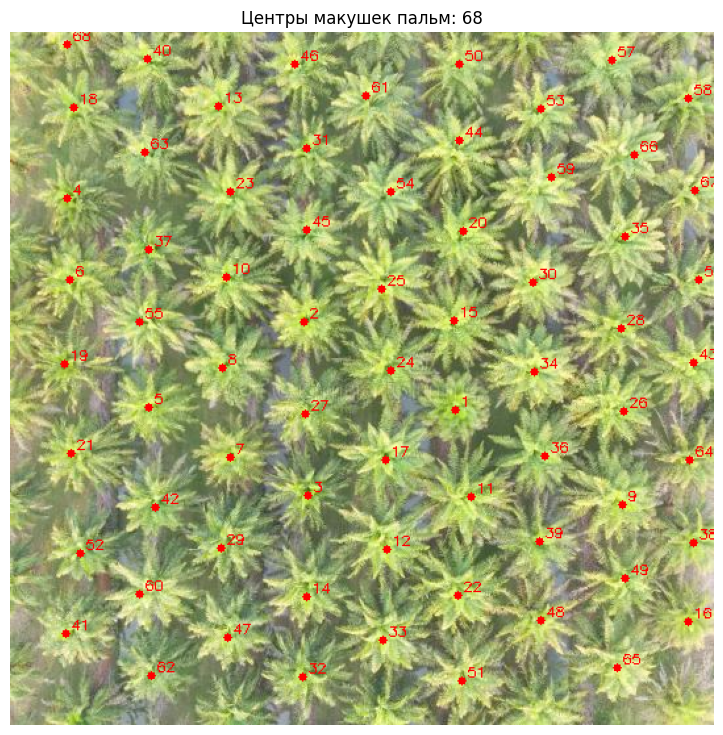

In [54]:
result = image_rgb.copy()

for i, (y, x) in enumerate(coordinates, start=1):

    cv2.circle(
        result,
        (int(x), int(y)),
        3,
        (255, 0, 0),
        -1
    )

    cv2.putText(
        result,
        str(i),
        (int(x) + 4, int(y) - 3),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.35,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(11, 9))
plt.imshow(result)
plt.title(f'Центры макушек пальм: {len(coordinates)}')
plt.axis('off')
plt.show()